# Where the two liquidus branches meet

Change one fusion enthalpy and predict which liquidus moves. OneSimulation solves the monotone composition closure equation. Check the returned composition against each single-component equation before interpreting the figure.

Run this cell with OneSimulation, NumPy and Matplotlib installed. Adjust the parameters and rerun to compare with the reference output below.


Eutectic temperature = 569.65 K
Eutectic liquid mole fraction of B = 0.67493
Composition closure error = 2.22e-16


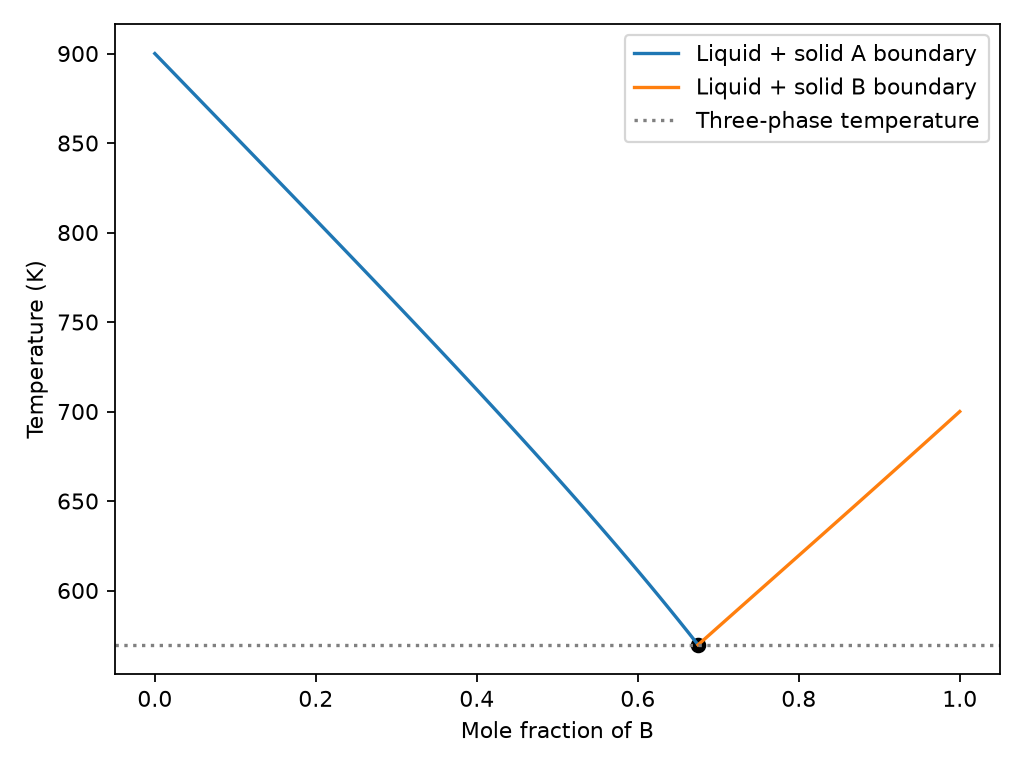

In [1]:
"""Ideal liquid in equilibrium with two immiscible pure solids."""
import numpy as np
import matplotlib.pyplot as plt
from onesim.numerics.nonlinear.kernels.local_solvers.inversion.bracketed_inverse import bisect_increasing

gas_constant = 8.314462618
melting_a, melting_b = 900.0, 700.0
fusion_a, fusion_b = 14500.0, 10000.0  # J per mol

def liquid_fraction(t, melting, heat):
    return np.exp(-heat / gas_constant * (1/t - 1/melting))

def fraction_sum(t):
    return liquid_fraction(t, melting_a, fusion_a) + liquid_fraction(t, melting_b, fusion_b)

temperature = float(bisect_increasing(fraction_sum, 1.0, 250., melting_b))
x_b = liquid_fraction(temperature, melting_b, fusion_b)
print(f"Eutectic temperature = {temperature:.2f} K")
print(f"Eutectic liquid mole fraction of B = {x_b:.5f}")
print(f"Composition closure error = {abs(fraction_sum(temperature)-1):.2e}")
ta = np.linspace(temperature, melting_a)
tb = np.linspace(temperature, melting_b)
plt.plot(1-liquid_fraction(ta, melting_a, fusion_a), ta, label="Liquid + solid A boundary")
plt.plot(liquid_fraction(tb, melting_b, fusion_b), tb, label="Liquid + solid B boundary")
plt.axhline(temperature, linestyle=":", color="grey", label="Three-phase temperature")
plt.scatter([x_b], [temperature], color="black")
plt.xlabel("Mole fraction of B")
plt.ylabel("Temperature (K)")
plt.legend()
plt.tight_layout()
plt.savefig("physics-eutectic.png", dpi=160)

plt.show()
